# Optimizing a reservoir's well controls with EnOpt

**Goal.** Maximize the net present value (NPV) of a small waterflood by choosing its wells' bottom-hole pressures, with APEX's ensemble optimizer EnOpt and the OPM Flow simulator. You will copy the example, read its configuration, validate it, run it, and look at what the optimizer changed: the controls, the NPV and the field's production.

**The model.** `3well` is the three-well tutorial of PET's `popt`: a 100 × 100 grid with two water injectors (`INJ-1`, `INJ-2`) at two corners and one producer (`PRO-1`) at a third, simulated for five years. Each well runs at a constant bottom-hole pressure (BHP) for the whole five years. Those three pressures are the controls.

**What you need.**

- OPM Flow (`flow`) on your `PATH`.
- APEX with the `reservoir` and `plots` extras (`uv sync --extra reservoir --extra plots`).
- About a minute for the first run: EnOpt evaluates 10 perturbed controls per iteration for 5 iterations, 50 simulations of a few seconds each, 4 at a time. Step 7 runs the same again with 10 iterations.

Run the notebook from a folder of your own: it copies the example into `./work` and keeps the job service's records in `./apex_home`.

In [1]:
%matplotlib inline
import json
import shutil
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from apex.client import Client
from apex.domain.services import OptimizationSummary
from apex.reporting.plots import GRID, INK, MUTED, POSTERIOR, PRIOR
from apex.services.examples import copy_example, examples_root, find_examples
from apex.services.settings import ExamplesSection

flow = shutil.which("flow")
print("OPM Flow:", flow or "not found: install it and put it on PATH before step 4")
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

OPM Flow: /usr/bin/flow


## Step 1: copy the example

The examples catalogue holds the case under the id `optimization/3well`. Copying it gives you files you can read and edit without touching the installed example.

In [2]:
catalogue = {e.id: e for e in find_examples(examples_root(ExamplesSection()))}
copied = copy_example(catalogue["optimization/3well"], Path("work"))
folder = copied.folder
config = folder / "enopt.toml"
print("copied to:", folder.relative_to(Path.cwd()))
for path in sorted(folder.iterdir()):
    print(" ", path.name)

# The copy reads the deck template from the installed example, and its own folder holds the
# files the deck includes (case_dir = ".").
simulator = tomllib.loads(config.read_text())["simulator"]["options"]
template = Path(simulator["deck_template_file"])
installed = str(template.parent)
print("deck template: the installed example's", template.name)

copied to: work/optimization/3well
  .apex-example.json
  TRUEPERMX.INC
  enopt.toml
  example.toml
deck template: the installed example's deck.mako


`enopt.toml` is the optimization and `TRUEPERMX.INC` the model's permeability field. The simulator's input deck is a template, `deck.mako`, which the copy reads from the installed example.

## Step 2: read the configuration

The deck template writes each well's pressure from the controls. The lines below are where it reads them: `${injbhp[0]}` is the first element of the control variable `injbhp`.

In [3]:
for line in template.read_text().splitlines():
    if "bhp[" in line:
        print(line)

'INJ-1'  WATER 'OPEN' BHP 2* ${injbhp[0]} /
'INJ-2'  WATER 'OPEN' BHP 2* ${injbhp[1]} /
 'PRO-1' 'OPEN' BHP 5* ${prodbhp[0]} /


Now the optimization itself, without its comments:

In [4]:
def setting(line: str) -> str:
    """Return a TOML line without its comment."""
    for index, char in enumerate(line):
        if char == "#" and line[:index].count('"') % 2 == 0:
            return line[:index].rstrip()
    return line.rstrip()


lines = (setting(line) for line in config.read_text().splitlines())
# The installed example's folder is shown as <examples>: it differs from machine to machine.
print("\n".join(s.replace(installed, "<examples>/optimization/3well") for s in lines if s))

[optimization]
name = "3well_enopt"
seed = 101122
[[controls.variables]]
name = "injbhp"
initial = [300.0, 250.0]
lower = 100.0
upper = 500.0
variance = 6250.0
[[controls.variables]]
name = "prodbhp"
initial = [100.0]
lower = 20.0
upper = 300.0
variance = 6250.0
[objective]
name = "npv"
options = { start = "1994-02-09", times = ["1995-01-01", "1996-01-01", "1997-01-01", "1998-01-01", "1999-01-01"], wop = 283.05, wgp = 0.0, wwp = 37.74, wwi = 12.58, disc = 0.08, obj_scaling = -1.0e6 }
[optimizer]
name = "enopt"
options = { ne = 10, maxiter = 5, tol = 1e-6, alpha = 0.2, beta = 0.1, nesterov = true, alpha_maxiter = 3, resample = 0, transform = true }
[simulator]
name = "opm_flow"
options = { deck_template_file = "<examples>/optimization/3well/deck.mako", case_dir = ".", flow_args = ["--tolerance-mb=1e-5", "--parsing-strictness=low"], timeout_s = 600 }
[execution]
name = "process"
options = { workers = 4 }
[output]
keep_simulations = "failed"


How to read it:

- `[[controls.variables]]` declares the controls. `injbhp` has two elements, one per injector, starting at 300 and 250 bar; `prodbhp` has one, starting at 100 bar. `lower` and `upper` bound them, and `variance` sets the size of EnOpt's random perturbations.
- `[objective]` is `npv`, computed from the field's cumulative totals at the five yearly report `times`:

  NPV = Σ_k (ΔFOPT_k · `wop` + ΔFGPT_k · `wgp` − ΔFWPT_k · `wwp` − ΔFWIT_k · `wwi`) / (1 + `disc`)^(t_k / 365)

  with ΔFOPT_k the oil produced in year k, ΔFWPT_k and ΔFWIT_k the water produced and injected, and t_k the days since `start`. Oil earns 283.05 per Sm³, produced water costs 37.74 and injected water 12.58 per Sm³, and the discount rate is 8% a year. APEX minimizes, so `obj_scaling = -1e6` turns the NPV into −NPV in millions: the more negative the objective, the better.
- `[optimizer]` is `enopt`: 10 perturbed copies of the controls (`ne`) estimate the gradient at each iteration, for at most 5 iterations (`maxiter`), with step size 0.2, momentum and the controls scaled to the unit cube (`transform`).
- `[simulator]` runs OPM Flow on the rendered deck (`case_dir = "."` was set by the copy, so the deck's include files come from the copy), and `[execution]` runs 4 simulations at a time.

## Step 3: validate before running

Validation checks the configuration and plans its cost without simulating anything. `max_evaluations` is a ceiling on the objective evaluations, here simulations.

In [5]:
client = Client(Path("apex_home"))  # the job service's records, kept in this folder

check = client.validate_optimization(config)
print("valid:", check.valid, check.errors or "")
plan = check.optimization
print(
    f"{plan.optimizer} on {plan.objective}: {plan.n_controls} controls, "
    f"at most {plan.max_evaluations} evaluations"
)

valid: True 
enopt on npv: 3 controls, at most 72 evaluations


## Step 4: run it

`submit_optimization` starts the optimization as a background job and `wait` waits for it. The run's folder is listed with the job.

In [6]:
def run(path: Path, timeout_s: float = 1800) -> OptimizationSummary:
    """Submit an optimization, wait for it and return its summary."""
    job = client.submit_optimization(path)
    status = client.wait(job.id, timeout_s=timeout_s, poll_s=1.0)
    print("job state:", status.state)
    if status.state != "complete":
        # No summary to read: say why the job ended instead.
        raise RuntimeError(f"the optimization job {status.state}: {status.error}")
    row = next((r for r in client.optimizations() if r["job"] == job.id), None)
    if row is None:
        raise RuntimeError(f"the job {job.id} recorded no optimization run")
    return client.optimization_summary(Path(row["path"]))


summary = run(config)
print("run:", summary.name, "|", summary.state, "|", summary.result["message"])
print("simulations:", summary.evaluations)

job state: complete
run: 3well_enopt | finished | Maximum number of iterations reached
simulations: 56


## Step 5: read the result

`summary.history` has a row for the start and for every accepted step, with the controls `x` and the objective. Turn the objective back into NPV (in millions) to read it the right way up.

In [7]:
def table(summary: OptimizationSummary) -> pd.DataFrame:
    """Return the run's NPV and controls at the start and after every accepted step."""
    rows = [r for r in summary.history if r["kind"] in ("start", "step")]
    frame = pd.DataFrame([r["x"] for r in rows], columns=summary.controls)
    frame.insert(0, "NPV (million)", [-r["objective"] for r in rows])
    frame.insert(0, "iteration", [r["iteration"] for r in rows])
    return frame


steps = table(summary)
steps.round(3)

,iteration,NPV (million),injbhp[0],injbhp[1],prodbhp
0,0,0.168,300.000,250.000,100.0
1,1,0.269,294.695,258.681,44.0
2,2,0.299,316.296,339.549,20.0
3,3,0.302,309.165,319.159,20.0
4,4,0.311,279.442,285.469,20.0
5,5,0.324,196.470,231.983,20.0


NPV: 0.168 -> 0.324 million (+93%)


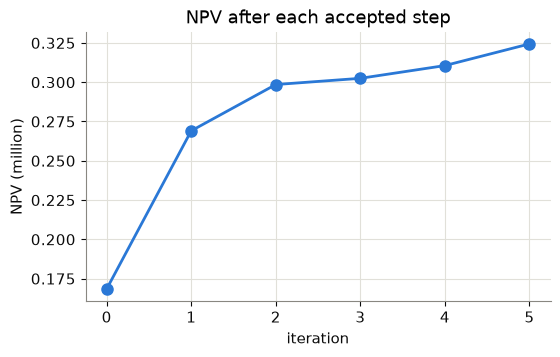

In [8]:
start, best = steps.iloc[0], steps.iloc[-1]
gain = best["NPV (million)"] / start["NPV (million)"] - 1
print(f"NPV: {start['NPV (million)']:.3f} -> {best['NPV (million)']:.3f} million ({gain:+.0%})")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(steps["iteration"], steps["NPV (million)"], color=POSTERIOR, lw=2, marker="o", ms=8)
ax.set_xlabel("iteration")
ax.set_ylabel("NPV (million)")
ax.set_title("NPV after each accepted step")
ax.set_xticks(steps["iteration"])
plt.show()

The three controls, each against its bounds (dashed). One panel per control, since the injectors' and the producer's pressures have different ranges:

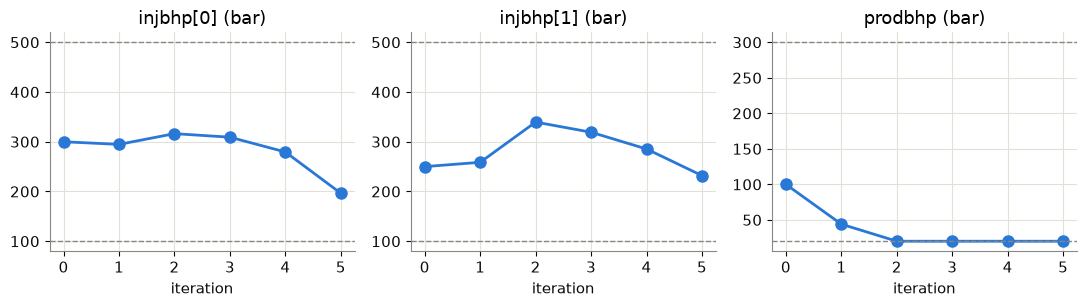

In [9]:
bounds = {"injbhp[0]": (100, 500), "injbhp[1]": (100, 500), "prodbhp": (20, 300)}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharex=True)
for ax, name in zip(axes, summary.controls, strict=True):
    ax.plot(steps["iteration"], steps[name], color=POSTERIOR, lw=2, marker="o", ms=8)
    for limit in bounds[name]:
        ax.axhline(limit, color=MUTED, lw=1, ls="--")
    ax.set_title(f"{name} (bar)")
    ax.set_xlabel("iteration")
    ax.set_xticks(steps["iteration"])
fig.tight_layout()
plt.show()

How to read the two figures:

- The NPV rises at every accepted step: EnOpt accepts a step only when it improves the objective.
- The producer's pressure falls to its lower bound, 20 bar, within two iterations. A lower producer pressure means a larger drawdown and more oil, and the bound keeps it there.
- The injectors' pressures first rise, then fall below their starting values. Injection supports the producer but costs money; once the producer draws hard, less injection pays better. The optimizer trades the two through the prices.
- The run stopped because it reached `maxiter = 5`, and its last step still improved the NPV. Step 7 checks whether more iterations help.

## Step 6: what changed in the field

Every simulation the run made is in the run folder's journal, `evaluations.jsonl`, with its objective value and the responses the NPV was computed from: the cumulative oil produced (FOPT), water produced (FWPT) and water injected (FWIT) at each report time. Find the simulations of the initial and of the final controls by their objective values.

In [10]:
journal = [json.loads(line) for line in (Path(summary.path) / "evaluations.jsonl").open()]
times = pd.to_datetime(
    json.loads((Path(summary.path) / "config.json").read_text())["objective"]["options"]["times"]
)
vectors = ["FOPT", "FWPT", "FWIT"]  # the priced totals, in this order, then TIME


def totals(objective: float) -> pd.DataFrame:
    """Return the cumulative totals (Sm3) of the simulation with this objective value."""
    entry = next(e for e in journal if np.isclose(e["value"], objective, rtol=0, atol=1e-12))
    values = np.asarray(entry["responses"][: len(vectors) * len(times)])
    return pd.DataFrame(
        values.reshape(len(vectors), len(times)).T, index=times.year, columns=vectors
    )


rows = [r for r in summary.history if r["kind"] in ("start", "step")]
initial, final = totals(rows[0]["objective"]), totals(rows[-1]["objective"])
pd.concat({"initial controls": initial, "final controls": final}, axis=1).round(1)

initial controls              final controls            
                 FOPT FWPT    FWIT           FOPT FWPT   FWIT
1995            154.0  0.5   304.4          275.4  1.3   34.4
1996            317.9  0.9   579.0          568.9  2.4   77.6
1997            480.9  1.2   846.2          860.8  3.3  125.1
1998            642.0  1.6  1113.8         1149.1  4.2  177.6
1999            802.2  1.9  1386.8         1435.9  5.0  233.6

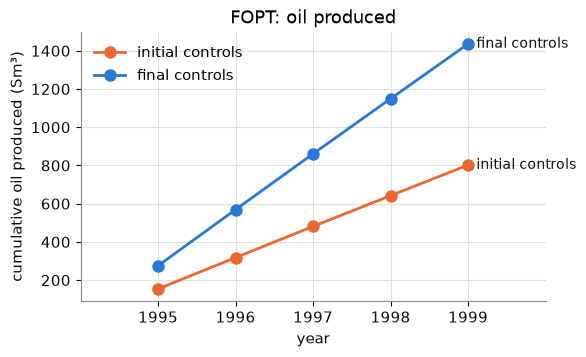

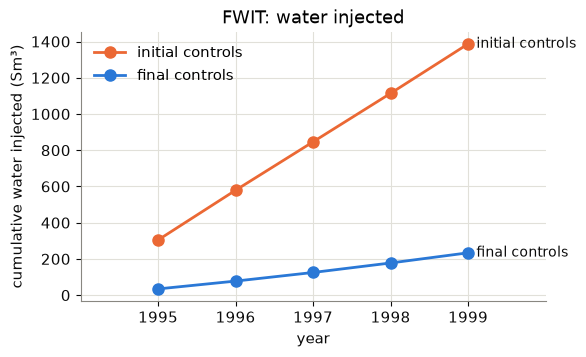

In [11]:
labels = {"FOPT": "oil produced", "FWIT": "water injected"}
for vector in ("FOPT", "FWIT"):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for frame, colour, name in (
        (initial, PRIOR, "initial controls"),
        (final, POSTERIOR, "final controls"),
    ):
        ax.plot(frame.index, frame[vector], color=colour, lw=2, marker="o", ms=8, label=name)
        ax.annotate(
            name,
            (frame.index[-1], frame[vector].iloc[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
            fontsize=10,
        )
    ax.set_xlabel("year")
    ax.set_ylabel(f"cumulative {labels[vector]} (Sm³)")
    ax.set_title(f"{vector}: {labels[vector]}")
    ax.set_xticks(frame.index)
    ax.legend(frameon=False, loc="upper left")
    ax.margins(x=0.25)
    plt.show()

Where the NPV comes from, year by year: each year's oil revenue and water costs, discounted. This repeats the objective's formula from the totals above, so its sum must equal the NPV the run reported.

In [12]:
options = json.loads((Path(summary.path) / "config.json").read_text())["objective"]["options"]
start_date = pd.Timestamp(options["start"])
days = np.array([(t - start_date).days for t in times])
discount = (1 + options["disc"]) ** (days / 365)


def cash(frame: pd.DataFrame) -> pd.DataFrame:
    """Return each year's discounted revenue and costs (million)."""
    steps = frame.diff().fillna(frame)  # the totals are zero at the start
    flows = pd.DataFrame(
        {
            "oil revenue": steps["FOPT"] * options["wop"],
            "produced water cost": -steps["FWPT"] * options["wwp"],
            "injected water cost": -steps["FWIT"] * options["wwi"],
        }
    )
    flows = flows.div(discount, axis=0) / 1e6
    flows["NPV contribution"] = flows.sum(axis=1)
    return flows


for name, frame, row in (("initial", initial, rows[0]), ("final", final, rows[-1])):
    flows = cash(frame)
    print(
        f"{name} controls: NPV {flows['NPV contribution'].sum():.4f} million "
        f"(the run: {-row['objective']:.4f})"
    )
cash(final).round(4)

initial controls: NPV 0.1685 million (the run: 0.1685)
final controls: NPV 0.3244 million (the run: 0.3244)


,oil revenue,produced water cost,injected water cost,NPV contribution
1995,0.0728,-0.0,-0.0004,0.0723
1996,0.0718,-0.0,-0.0005,0.0713
1997,0.0661,-0.0,-0.0005,0.0656
1998,0.0605,-0.0,-0.0005,0.0600
1999,0.0557,-0.0,-0.0005,0.0552


With the final controls the field produces almost twice the oil over five years and injects far less water: the producer's low pressure does most of the work, and the injectors' lower pressures save injection costs. Little water reaches the producer within five years in either case: the final controls produce slightly more water (FWPT 5.0 against 1.9 Sm³ by 1999), but at a cost too small to show in the table's rounding, so oil revenue dominates every year's contribution. The yearly contributions shrink with time only through the discounting: the field produces about the same oil each year.

## Step 7: give it more iterations

The first run stopped at its iteration limit with its last step still improving. Write a copy with a new name and `maxiter = 10`, and run it the same way. A new name gives it a run folder of its own, so the first run is kept for comparison.

In [13]:
text = config.read_text()
longer = folder / "enopt_maxiter10.toml"
longer.write_text(
    text.replace('name = "3well_enopt"', 'name = "3well_enopt_maxiter10"').replace(
        "maxiter = 5", "maxiter = 10"
    )
)
check = client.validate_optimization(longer)
print("valid:", check.valid, "| at most", check.optimization.max_evaluations, "evaluations")

summary10 = run(longer)
steps10 = table(summary10)
print(summary10.result["message"])
steps10.round(3)

valid: True | at most 142 evaluations


job state: complete
EnOpt failed to find an improving step.


,iteration,NPV (million),injbhp[0],injbhp[1],prodbhp
0,0,0.168,300.000,250.000,100.0
1,1,0.269,294.695,258.681,44.0
2,2,0.299,316.296,339.549,20.0
3,3,0.302,309.165,319.159,20.0
4,4,0.311,279.442,285.469,20.0
5,5,0.324,196.470,231.983,20.0


In [14]:
print(
    f"maxiter = 5:  {len(steps) - 1} steps accepted, "
    f"NPV {steps['NPV (million)'].iloc[-1]:.4f} million ({summary.result['message']})"
)
print(
    f"maxiter = 10: {len(steps10) - 1} steps accepted, "
    f"NPV {steps10['NPV (million)'].iloc[-1]:.4f} million ({summary10.result['message']})"
)

maxiter = 5:  5 steps accepted, NPV 0.3244 million (Maximum number of iterations reached)
maxiter = 10: 5 steps accepted, NPV 0.3244 million (EnOpt failed to find an improving step.)


The two runs share their seed, so their first five steps are the same. The longer run then stops on its own: at the sixth iteration none of EnOpt's trial steps (`alpha_maxiter = 3` shrinking step sizes along its gradient estimate) improved the NPV. More iterations do not help with these settings: the run has reached what its gradient estimate can find from here, a local optimum for these options, not necessarily the best controls. To learn more about the problem, change one option at a time in a renamed copy, for example:

- `ne`: more perturbations give a less noisy gradient, at more simulations per iteration;
- `alpha`: the step size; too large a step is rejected and retried (`alpha_maxiter`), too small a step makes slow progress;
- `seed`: a different seed draws different perturbations; repeat a run with a few seeds before drawing conclusions from one.

## The same from the terminal

The steps above are also commands. From the folder holding `work/`:

```bash
uv run apex validate work/optimization/3well/enopt.toml
uv run apex optimize work/optimization/3well/enopt.toml
uv run apex optimize --resume work/optimization/3well/runs/3well_enopt
```

`apex optimize` writes the same run folder (`history.jsonl`, `result.json`, `evaluations.jsonl`), and `--resume` continues a stopped run from its last accepted step without repeating the simulations already in the journal.

## What to read next

- The optimization guide: all optimizers, objectives, controls over time (`control_schedule`), robust optimization over several realizations and multi-objective runs: <https://lanhill.github.io/APEX-public/optimization.html>.
- The examples catalogue has more simulated optimizations, for example `toy/toy_reservoir_robust_npv`, NPV's mean against its spread over realizations.